# 3. Model and policy

AUC alone does not run a lending business. The policy question is: **at a given default rate, how many people do we approve?** All numbers are read from `reports/metrics.json`, produced by `python -m src.pipeline`.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

METRICS = json.loads((ROOT / "reports" / "metrics.json").read_text())
SOURCE = METRICS["meta"]["data_source"]
display(Markdown(
    "> **Data source: real Home Credit data.**" if METRICS["meta"]["resume_safe"]
    else "> ⚠️ **SYNTHETIC DATA. Plumbing check only; do not read these numbers as findings.**"))

def load_application():
    """Real CSV if present and the reports came from it, otherwise the synthetic stand-in."""
    from src import synthetic
    path = ROOT / "data" / "application_train.csv"
    if METRICS["meta"]["resume_safe"] and path.exists():
        from src.pipeline import APP_COLUMNS
        return pd.read_csv(path, usecols=APP_COLUMNS)
    return synthetic.make_application_train(n=METRICS["meta"]["n_rows"], seed=METRICS["meta"]["seed"])


> **Data source: real Home Credit data.**

In [2]:
m = METRICS
display(pd.DataFrame(m["models"]["comparison"]).T.rename(columns={"auc_val": "val AUC", "auc_test": "test AUC"}))
d = m["discrimination_test"]
print(f"Production model test AUC {d['auc']} (95% CI {d['auc_ci95']}), Gini {d['gini']}, KS {d['ks']}")
print("Tuning trials:", len(m["models"]["tuning_trials"]), "| best params:", m["models"]["best_params"] or "defaults")

,val AUC,test AUC
logistic_regression,0.7349,0.7400
xgboost_unconstrained,0.7580,0.7613
xgboost_monotone_tuned,0.7596,0.7630


Production model test AUC 0.763 (95% CI [0.7556, 0.7693]), Gini 0.526, KS 0.3919
Tuning trials: 12 | best params: {'max_depth': 5, 'learning_rate': 0.05, 'min_child_weight': 3, 'subsample': 0.9, 'colsample_bytree': 0.8, 'reg_lambda': 10.0}


## Why a monotone-constrained, calibrated model

Risk may never *fall* as credit-to-income rises or *rise* as the external score rises: easier to defend to a risk committee. Platt scaling makes the PD behave like a probability so cutoffs mean something.

ECE before: 0.0029 | after Platt: 0.0021


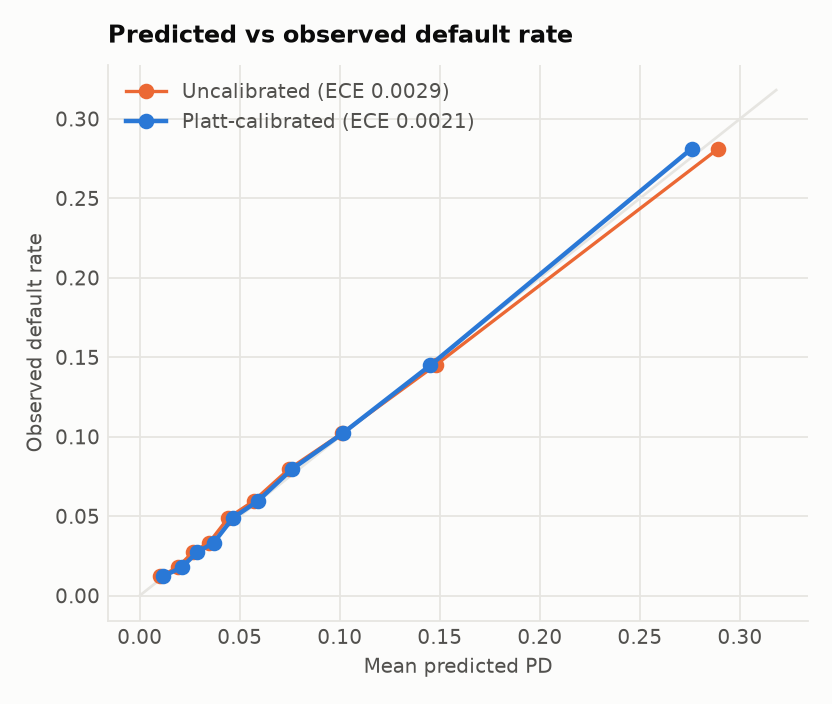

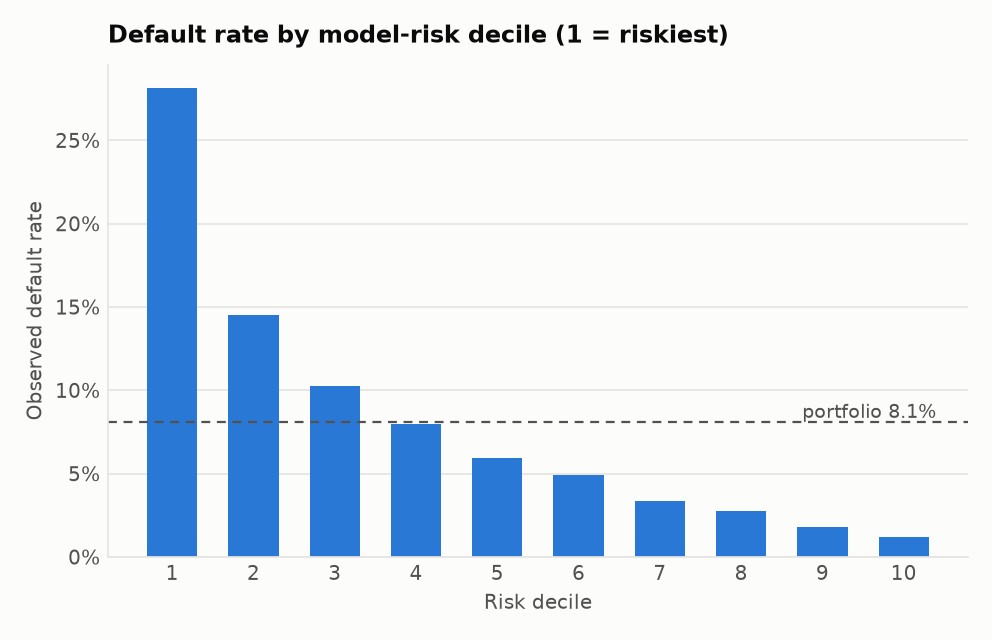

In [3]:
c = m["calibration"]; print("ECE before:", c["ece_uncalibrated"], "| after Platt:", c["ece_calibrated"])
display(Image(filename=str(ROOT / "reports/figures/calibration.png"), width=420)); display(Image(filename=str(ROOT / "reports/figures/deciles.png"), width=520))

## The policy comparison

Rules can only *remove* applicants, so rules + ML can never approve more than the rules alone. The fair question is therefore: against the **best rules-only policy** (income floor, repayment caps, loan-to-income cap **and a bureau-score floor**, tuned on validation), how much lower is the default rate at the same approval rate, and can rules reach the model's default rate at all?

,approval rate,default among approved
current rules,85.56%,8.56%
"tuned rules, same target",73.47%,6.30%
"tuned rules, same approval",77.69%,6.89%
rules + ML,77.31%,6.30%


Target reached by rules-only on validation: True
Default-rate cut vs tuned rules at the same approval rate (pts): {'point': 0.59, 'ci95': [0.47, 0.7]}
Approval uplift vs tuned rules at the same target (pts): {'point': 3.84, 'ci95': [3.63, 4.05]}


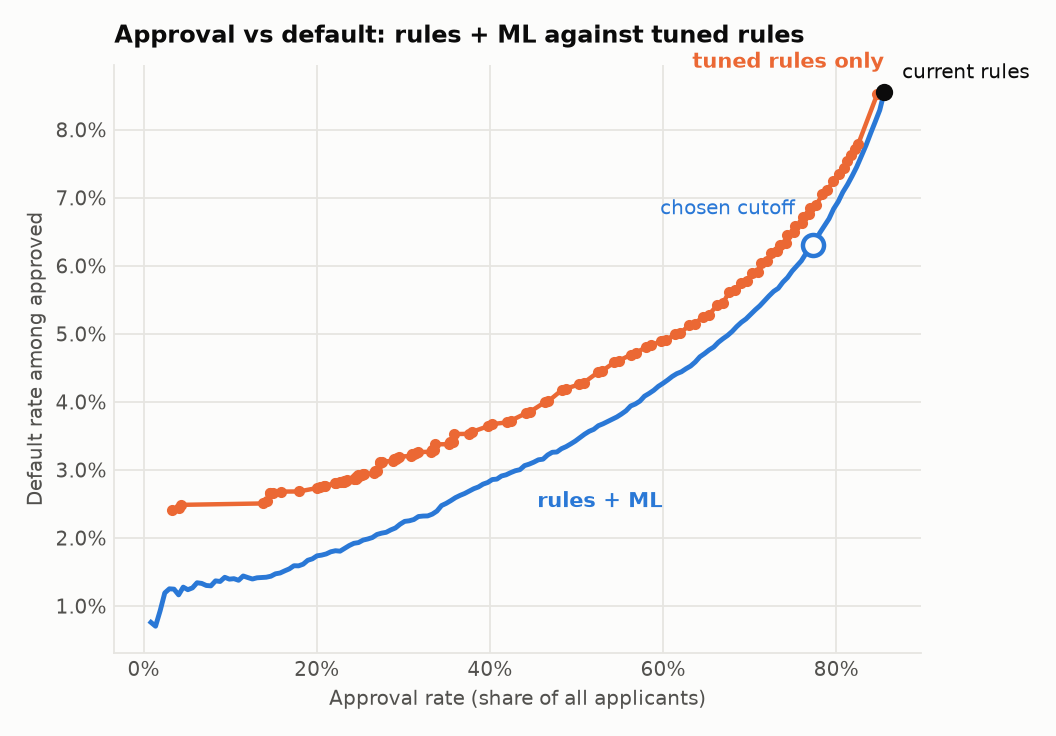

In [4]:
c = m["comparison"]
tbl = pd.DataFrame({k: {"approval rate": v["approval_rate"], "default among approved": v["default_rate_among_approved"]}
                    for k, v in [("current rules", c["current_rules_only"]), ("tuned rules, same target", c["tuned_rules_only_same_target"]), ("tuned rules, same approval", c["tuned_rules_only_same_approval"]), ("rules + ML", c["rules_plus_ml"])]}).T
display(tbl.style.format("{:.2%}"))
print("Target reached by rules-only on validation:", c["tuned_rules_only_same_target"]["target_reached_on_validation"])
print("Default-rate cut vs tuned rules at the same approval rate (pts):", c["default_cut_vs_tuned_rules_same_approval_pts"])
print("Approval uplift vs tuned rules at the same target (pts):", c["approval_uplift_vs_tuned_rules_pts"])
display(Image(filename=str(ROOT / "reports/figures/frontier.png"), width=620))

In [5]:
scores = pd.read_parquet(ROOT / "reports/test_scores.parquet")
ok = scores.rules_pass.values
rows = []
for t1 in np.quantile(scores.pd[ok], [0.2, 0.4, 0.5, 0.6, 0.8, 1.0]):
    a = ok & (scores.pd.values <= t1)
    rows.append({"PD cutoff": round(t1, 4), "approval rate": a.mean(), "default among approved": scores.y.values[a].mean(),
                 "bad loans per 1,000 applicants": 1000 * (a & (scores.y.values == 1)).mean()})
pd.DataFrame(rows).style.format({"approval rate": "{:.1%}", "default among approved": "{:.2%}", "bad loans per 1,000 applicants": "{:.1f}"})

,PD cutoff,approval rate,default among approved,"bad loans per 1,000 applicants"
0,0.026200,17.1%,1.59%,2.7
1,0.043900,34.2%,2.46%,8.4
2,0.055500,42.8%,2.98%,12.7
3,0.070900,51.3%,3.56%,18.3
4,0.126500,68.4%,5.10%,34.9
5,0.753400,85.6%,8.56%,73.2


## Caveats that matter

- Training labels exist only for loans that were originally **granted** (selection bias, no reject inference).
- Cutoffs were picked on validation and evaluated on a separate test split; CIs are bootstrap over the test set.
- The policy comparison is only as good as the rules grid searched; a richer rules engine would narrow the gap.